/var/folders/ll/hm35mj650fs_spb22x5qqnqh0000gn/T/ipykernel_8930/2187122328.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


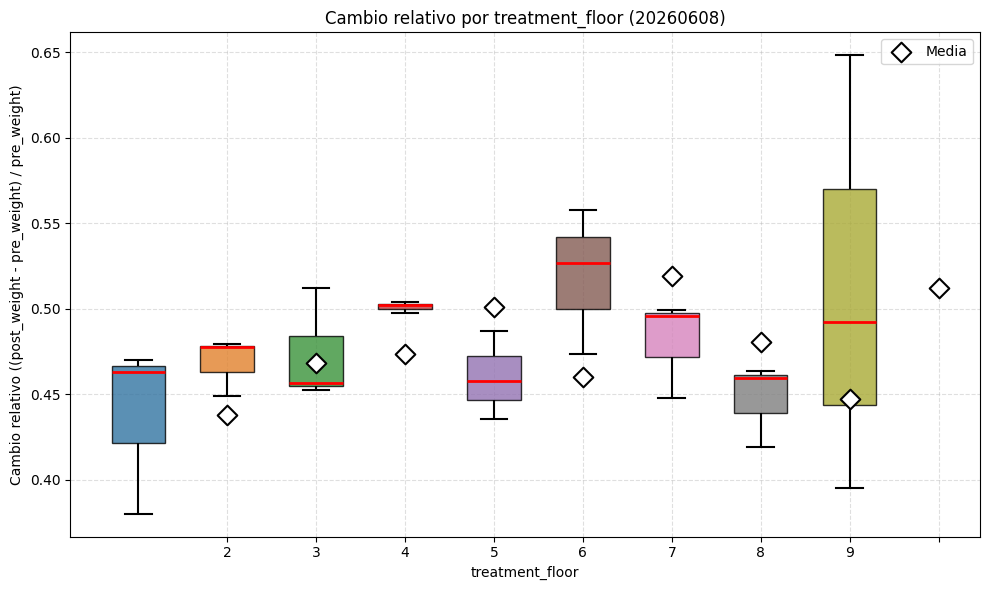

In [14]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fecha = '20260608'  # por ejemplo '20260608'
base_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments") / fecha
trays_path = base_dir / "trays.csv"

df = pd.read_csv(trays_path)
df["treatment_floor"] = pd.to_numeric(df["treatment_floor"], errors="coerce")
df["pct_change"] = (df["post_weight"] - df["pre_weight"]) / df["pre_weight"]

plt.figure(figsize=(10, 6))
# Boxplot por treatment_floor
sns.boxplot(
    data=df,
    x="treatment_floor",
    y="pct_change",
    palette="tab10",
    width=0.6,
    medianprops={"color": "red", "linewidth": 2},
    whiskerprops={"color": "k", "linewidth": 1.5},
    capprops={"color": "k", "linewidth": 1.5},
    boxprops={"alpha": 0.8, "edgecolor": "k"}
)

# Media por treatment_floor como rombo blanco
mean_df = df.groupby("treatment_floor", as_index=False)["pct_change"].mean()
plt.scatter(
    mean_df["treatment_floor"],
    mean_df["pct_change"],
    marker="D",
    s=100,
    facecolors="white",
    edgecolors="k",
    linewidths=1.5,
    zorder=10,
    label="Media"
)

plt.xlabel("treatment_floor")
plt.ylabel("Cambio relativo ((post_weight - pre_weight) / pre_weight)")
plt.title(f"Cambio relativo por treatment_floor ({fecha})")
plt.xticks(sorted(df["treatment_floor"].unique()))
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="best")
plt.tight_layout()
plt.show()